In [1]:
import numpy as np
import matplotlib.pyplot as plt
from classy import Class
from getdist.mcsamples import loadMCSamples

# =========================
# 1. LOAD CHAINS
# =========================
chains = loadMCSamples("../mavan_desy5/pngb_desy5")

# =========================
# 2. SETTINGS
# =========================
nsamples = 200
z_grid = np.linspace(0, 10, 200)

all_weff = []
all_wphi = []

weights = chains.weights
indices = np.random.choice(
    len(weights),
    size=nsamples,
    p=weights / weights.sum()
)

print(f"Starting reconstruction for {nsamples} samples...")

# =========================
# 3. LOOP
# =========================
for k, idx in enumerate(indices):

    cosmo = Class()

    try:

        p = lambda name: chains.samples[idx, chains.index[name]]

        params = {
            'omega_b': p('omega_b'),
            'omega_cdm': p('omega_cdm'),
            'H0': p('H0'),
            'A_s': p('A_s'),
            'n_s': p('n_s'),

            'N_ur': 0.044,
            'N_ncdm': 1,
            'm_ncdm': 0.06,
            'T_ncdm': 0.71611,
            'deg_ncdm': 3,

            'beta_ncdm': p('beta_ncdm'),

            'scf_parameters':
                f"{p('scf_lambda')}, -7, 0.0, 0.0, 1.0, 0.0",

            'Omega_fld': 0.0,
            'Omega_scf': -1,
            'Omega_Lambda': 0.0,

            'attractor_ic_scf': 'no',
            'scf_tuning_index': 1,

            'output': 'mPk',
            'P_k_max_1/Mpc': 1.0,
        }

        cosmo.set(params)
        cosmo.compute()

        bg = cosmo.get_background()

        # =========================
        # Background quantities
        # =========================
        z_bg = bg['z']

        rho_scf = bg['(.)rho_scf']
        p_scf   = bg['(.)p_scf']

        rho_nu = bg['(.)rho_ncdm[0]']
        p_nu   = bg['(.)p_ncdm[0]']

        Hconf = bg['H [1/Mpc]'] / (1. + z_bg)
        dphi  = bg['phi\'_scf']

        beta_val = p('beta_ncdm')

        # =========================
        # w_phi
        # =========================
        w_phi = p_scf / rho_scf

        # =========================
        # w_eff
        # =========================
        w_eff = (
            w_phi
            + beta_val * dphi * (rho_nu - 3*p_nu)
            / (3 * Hconf * rho_scf)
        )

        # CLASS usually outputs descending z
        order = np.argsort(z_bg)

        wphi_interp = np.interp(
            z_grid,
            z_bg[order],
            w_phi[order]
        )

        weff_interp = np.interp(
            z_grid,
            z_bg[order],
            w_eff[order]
        )

        all_wphi.append(wphi_interp)
        all_weff.append(weff_interp)

        print(f"Success: {k+1}/{nsamples}", end="\r")

    except Exception as e:
        print(f"\nError at index {idx}: {e}")

    finally:
        cosmo.struct_cleanup()
        cosmo.empty()

# =========================
# 4. STATISTICS
# =========================
all_wphi = np.array(all_wphi)
all_weff = np.array(all_weff)

# ---- w_phi
med_wphi = np.percentile(all_wphi, 50, axis=0)
low68_wphi, high68_wphi = np.percentile(all_wphi, [16,84], axis=0)
low95_wphi, high95_wphi = np.percentile(all_wphi, [2.5, 97.5], axis=0)
# ---- w_eff
med_weff = np.percentile(all_weff, 50, axis=0)
low68_weff, high68_weff = np.percentile(all_weff, [16,84], axis=0)
low95_weff, high95_weff = np.percentile(all_weff, [2.5, 97.5], axis=0)

# =========================
# Find phantom crossing
# =========================

crossings = np.where(
    np.diff(np.sign(med_weff + 1))
)[0]

if len(crossings) > 0:

    i = crossings[0]

    # points around the crossing
    z1, z2 = z_grid[i], z_grid[i+1]
    w1, w2 = med_weff[i], med_weff[i+1]

    # linear interpolation
    z_cross = z1 + (-1 - w1) * (z2 - z1) / (w2 - w1)

    print(f"\nPhantom crossing redshift: z = {z_cross:.3f}")

else:
    print("\nNo phantom crossing found.")


Starting reconstruction for 200 samples...

Error at index 939: 

Error in Class: background_init(L:866) :condition (pba->shooting_failed == _TRUE_) is true; Shooting failed, try optimising input_get_guess(). Error message:

input_shooting(L:653) :error in input_find_root(&xzero, &fevals, ppr->tol_shooting_deltax_rel, &fzw, errmsg);
=>input_find_root(L:928) :error in input_fzerofun_1d(x1, pfzw, &f1, errmsg);
=>input_fzerofun_1d(L:1003) :error in input_try_unknown_parameters(&input, 1, pfzw, output, error_message);
=>input_try_unknown_parameters(L:1406) :error in background_init(&pr,&ba);
=>background_init(L:882) :error in background_solve(ppr,pba);
=>background_solve(L:2018) :error in generic_evolver(background_derivs, loga_ini, loga_final, pvecback_integration, used_in_output, pba->bi_size, &bpaw, ppr->tol_background_integration, ppr->smallest_allowed_variation, background_timescale, ppr->background_integration_stepsize, pba->loga_table, pba->bt_size, background_sources, ((void *)0), 

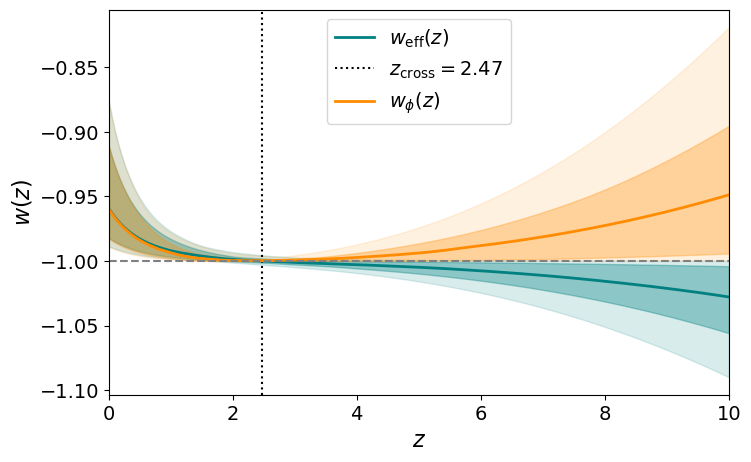

In [2]:
# =========================
# 5. PLOT
# =========================
plt.figure(figsize=(8,5))

# w_eff
plt.fill_between(
    z_grid,
    low95_weff,
    high95_weff,
    alpha=0.15,
    color='teal'
)
plt.fill_between(
    z_grid,
    low68_weff,
    high68_weff,
    alpha=0.35,
    color='teal'
)

plt.plot(
    z_grid,
    med_weff,
    color='teal',
    lw=2,
    label=r'$w_{\rm eff}(z)$'
)
plt.axvline(
    z_cross,
    color='black',
    ls=':',
    lw=1.5,
    label=fr'$z_{{\rm cross}}={z_cross:.2f}$'
)
# w_phi
plt.fill_between(
    z_grid,
    low95_wphi,
    high95_wphi,
    alpha=0.12,
    color='darkorange'
)
plt.fill_between(
    z_grid,
    low68_wphi,
    high68_wphi,
    alpha=0.30,
    color='darkorange'
)

plt.plot(
    z_grid,
    med_wphi,
    color='darkorange',
    lw=2,
    label=r'$w_{\phi}(z)$'
)

plt.axhline(-1, ls='--', color='gray')

plt.xlabel('$z$', fontsize=16)
plt.ylabel(r'$w(z)$', fontsize=16)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.xlim(0,10)

plt.legend(fontsize=14)

plt.savefig("wphi_weff_reconstruction.pdf", bbox_inches='tight')

plt.show()